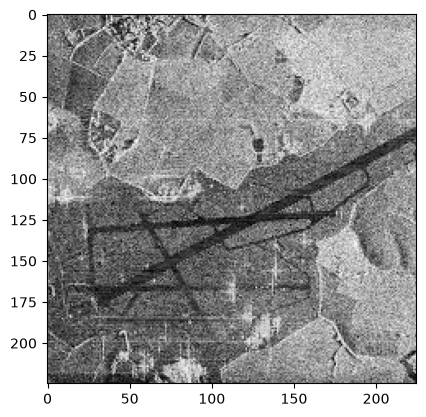

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
import copy

image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap="gray")

Всего отрезков: 2
Самый длинный: 235.3 px, (15, 179) — (223, 69)


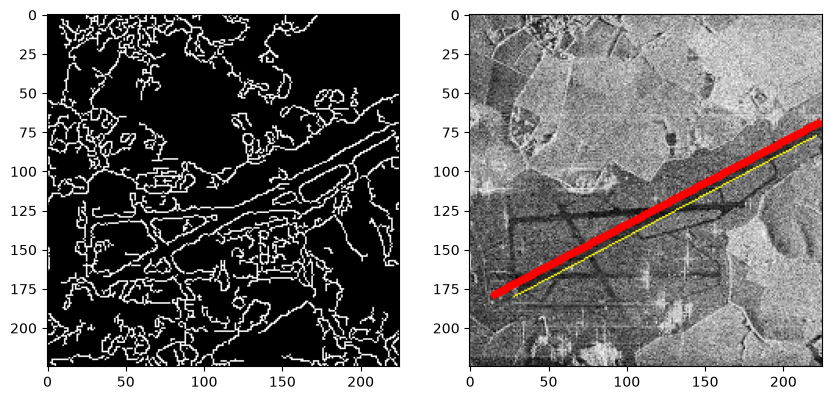

In [10]:
gray_f = cv2.medianBlur(image_gray, 5)
canny = cv2.Canny(gray_f, 50, 150, apertureSize=3)
lines = cv2.HoughLinesP(canny, rho=1, theta=np.pi / 180,
                        threshold=100, minLineLength=100, maxLineGap=20)

image_lines = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
max_length = 0
longest_line = None

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line.ravel()
        cv2.line(image_lines, (x1, y1), (x2, y2), (255, 255, 0), 1)

    for line in lines:
        x1, y1, x2, y2 = line.ravel()
        length = np.hypot(x2 - x1, y2 - y1)
        if length > max_length:
            max_length = length
            longest_line = (x1, y1, x2, y2)

    if longest_line is not None:
        x1, y1, x2, y2 = longest_line
        cv2.line(image_lines, (x1, y1), (x2, y2), (255, 0, 0), 3)
        print(f"Всего отрезков: {len(lines)}")
        print(f"Самый длинный: {max_length:.1f} px, ({x1}, {y1}) — ({x2}, {y2})")
else:
    print("Отрезки не найдены.")

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(canny, cmap="gray")

plt.subplot(1, 2, 2)
plt.imshow(image_lines)
plt.show()

In [11]:
# Адаптивная бинаризация 
th3 = cv2.adaptiveThreshold(gray_f, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                            cv2.THRESH_BINARY_INV, 71, 21)

In [12]:
# Глобальная бинаризация
T = 100
bin_img = copy.deepcopy(gray_f)
bin_img[gray_f > T] = 0
bin_img[gray_f <= T] = 255

for t in (50, 75, 100, 125, 150):
    print(f"T = {t:3d}: доля белых = {np.count_nonzero(gray_f <= t) / gray_f.size:.4f}")
# Метод Оцу
ret_otsu, th2 = cv2.threshold(gray_f, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print(f"Порог Оцу: {ret_otsu:.0f}")

T =  50: доля белых = 0.0207
T =  75: доля белых = 0.0790
T = 100: доля белых = 0.2605
T = 125: доля белых = 0.4503
T = 150: доля белых = 0.6365
Порог Оцу: 128


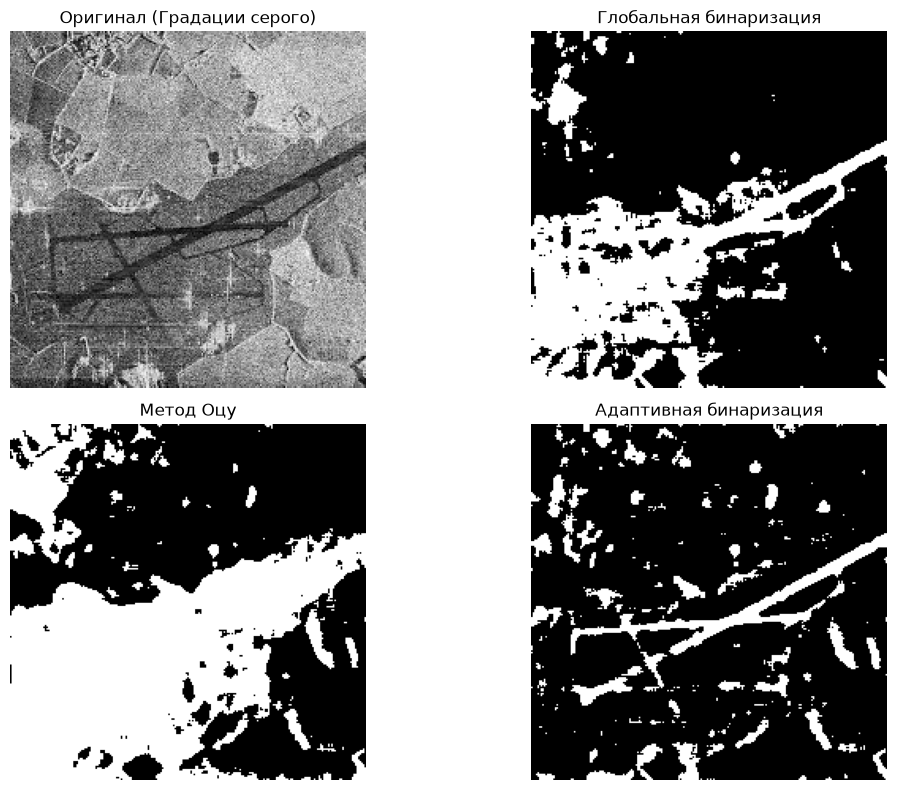

In [17]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.title("Оригинал (Градации серого)")
plt.imshow(image_gray, cmap="gray")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.title(f"Глобальная бинаризация")
plt.imshow(bin_img, cmap="gray")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.title(f"Метод Оцу")
plt.imshow(th2, cmap="gray")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.title("Адаптивная бинаризация")
plt.imshow(th3, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()

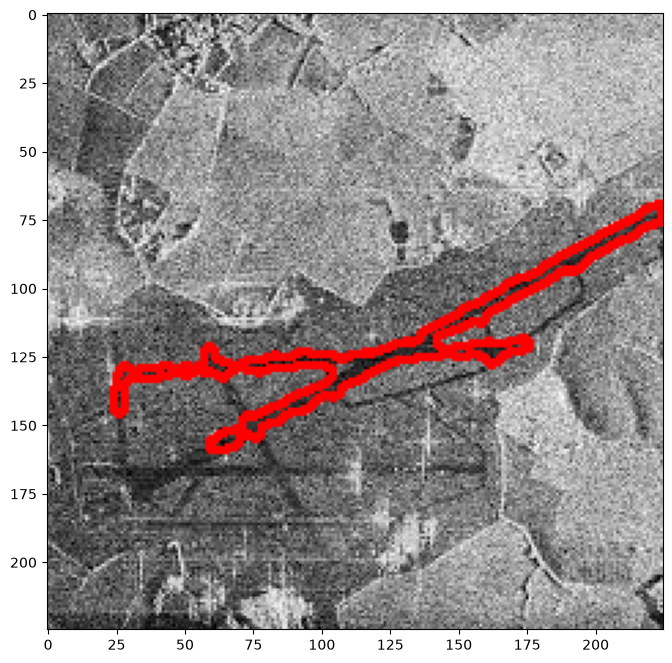

In [15]:
median = cv2.medianBlur(image_gray, 5)
blurred = cv2.GaussianBlur(median, (7, 7), 0)

thresh = cv2.adaptiveThreshold(
    blurred, 
    255, 
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
    cv2.THRESH_BINARY_INV, 
    11, 
    2
)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
clean_mask = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel)

contours, _ = cv2.findContours(
    clean_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

lane_image = image.copy()


for c in contours:
    if cv2.contourArea(c) > 500:
        cv2.drawContours(
            lane_image,
            [c],          
            -1,
            (0, 0, 255),
            2
        )

plt.figure(figsize=(10, 8))

plt.imshow(cv2.cvtColor(lane_image, cv2.COLOR_BGR2RGB))

plt.show()

In [24]:
print("Сравнены три метода: глобальная бинаризация, Оцу и адаптивная. Скан порогов делался только для глобальной,так как у Оцу порог вычисляется сам, а у адаптивной он локальный. Скан порогов показал, что глобальная бинаризация при T >= 125 уже “съедает” фон,а Оцу с порогом 128 даёт 47% белых - почти половину кадра при реальной площади дороги ~10-20%. Поэтому для выделения дорожной полосы выбрана адаптивная бинаризация");

Сравнены три метода: глобальная бинаризация, Оцу и адаптивная. Скан порогов делался только для глобальной,так как у Оцу порог вычисляется сам, а у адаптивной он локальный. Скан порогов показал, что глобальная бинаризация при T >= 125 уже “съедает” фон,а Оцу с порогом 128 даёт 47% белых - почти половину кадра при реальной площади дороги ~10-20%. Поэтому для выделения дорожной полосы выбрана адаптивная бинаризация
